# Reading Sharpe as a Risk Target

<a href="https://www.kaggle.com/code/addarm/sharpe-as-risk-target" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

![Sharpe as a Risk Target](https://raw.githubusercontent.com/adamd1985/quant_research/refs/heads/main/images/sharpe_as_risk_target.png)

The Sharpe ratio is the number every backtest reports and every allocator ranks by. It divides excess return by volatility, so a higher number means more return for each unit of risk. We usually use it to rank strategies. Can the same number also tell us how hard to push one?

This is the third article in a series. [The Mathematics of a Retail Trader's Ruin](https://medium.com/hecatus-research/the-mathematics-of-a-retail-traders-ruin-3521d6556b71) showed that positive expectancy isn't enough, because path and ruin matter. [Kelly Under Uncertainty](https://www.kaggle.com/code/addarm/kelly-under-uncertainty) showed that estimation error becomes sizing error. Here we ask the sizing question in continuous time, with stock-like returns instead of coin flips. We re-derive what we need, so this one stands on its own.

## Notebook Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

## What Sharpe Measures

Take a strategy with expected return $\mu$ per year, volatility $\sigma$ per year, and a cash rate $r$ that we could earn instead. Sharpe (1966, 1994) defined the ratio of excess return to volatility:

$$
SR=\frac{\mu-r}{\sigma}.
$$

Our running example is Strategy A with $r=2\%$, $\mu=10\%$ and $\sigma=16\%$. The excess return is $\mu-r=8\%$, so $SR=0.50$.

Sharpe is a ratio, so it ignores scale. Borrow cash and hold $f>0$ times the strategy. The excess return becomes $f(\mu-r)$, the volatility becomes $f\sigma$, and the $f$ cancels:

$$
\frac{f(\mu-r)}{f\sigma}=SR.
$$

Levering leaves Sharpe unchanged (for $f>0$, since a short position flips the sign). That's why Sharpe ranks strategies well, and also why it can't be a sizing rule on its own. Every leverage level shares one Sharpe, so which level do we pick?

## Volatility Costs Compound Growth

A gain of $x$ followed by a loss of $x$ leaves $(1+x)(1-x)=1-x^2$, a net loss even though the average return is zero. Volatility drags on compounding.

Now the continuous-time version. The risky asset price $S_t$ follows geometric Brownian motion with constant drift $\mu$ and volatility $\sigma$, driven by a Brownian motion $B_t$. Cash grows at $r$. We hold a fraction $f$ of wealth $W_t$ in the risky asset and the rest in cash, rebalanced continuously. Taking the log of wealth with Itô's lemma adds a correction of $-\tfrac12f^2\sigma^2\,dt$:

$$
\begin{aligned}
\frac{dS_t}{S_t}&=\mu\,dt+\sigma\,dB_t\\
\frac{dW_t}{W_t}&=r\,dt+f(\mu-r)\,dt+f\sigma\,dB_t\\
d\log W_t&=g(f)\,dt+f\sigma\,dB_t\\
g(f)&=r+f(\mu-r)-\tfrac12f^2\sigma^2.
\end{aligned}
$$

Here $g(f)$ is the growth rate of log wealth. The term $f(\mu-r)$ pays for exposure to the excess return. The term $\tfrac12f^2\sigma^2$ charges for the variance that exposure adds. It's the volatility drag from the first article, now exact.

Integrating gives $\log(W_t/W_0)=g\,t+f\sigma B_t$. Brownian motion has mean zero, so $\mathbb E[\log(W_t/W_0)]/t=g$ exactly for any $t$. Along a single path the realised growth rate converges to $g$ almost surely as $t$ grows.

## The Growth-Optimal Exposure

Differentiate $g$ with respect to $f$, set the derivative to zero and solve:

$$
\begin{aligned}
g(f)&=r+f(\mu-r)-\tfrac12f^2\sigma^2\\
g'(f)&=(\mu-r)-f\sigma^2\\
0&=(\mu-r)-f^*\sigma^2\\
f^*&=\frac{\mu-r}{\sigma^2}\\
g''(f)&=-\sigma^2<0.
\end{aligned}
$$

The second derivative is negative, so $g$ is concave and $f^*$ is the maximum. In words, the best exposure is the excess return per unit of variance. For Strategy A, $f^*=0.08/0.0256=3.125$.

The assumptions are the usual ones: one risky asset, no costs or taxes, constant and known $\mu$, $\sigma$ and $r$, continuous rebalancing, and no limits on leverage or shorting. Kelly (1956) first maximised log growth for repeated bets, and Breiman (1961) proved its long-run optimality properties. Cover and Thomas (chapter 16) give the portfolio version. Merton (1969, 1971) solved the continuous-time problem for an investor with risk-aversion coefficient $\gamma$, and his share is $(\mu-r)/(\gamma\sigma^2)$. Log utility is $\gamma=1$, so $f^*$ is Merton's answer for that case.

## Sharpe's Second Reading

Write the optimum as one over volatility times the Sharpe ratio, then substitute it back into $g$:

$$
\begin{aligned}
f^*&=\frac1\sigma\cdot\frac{\mu-r}{\sigma}=\frac{SR}{\sigma}\\
g(f^*)&=r+\frac{SR}{\sigma}(\mu-r)-\frac12\frac{SR^2}{\sigma^2}\sigma^2\\
&=r+SR^2-\tfrac12SR^2\\
&=r+\tfrac12SR^2.
\end{aligned}
$$

Two things fall out. The best growth rate we can reach is $r+\tfrac12SR^2$, so Sharpe sets the ceiling. And the exposure that reaches it is $SR/\sigma$, so volatility sets how much leverage the ceiling costs. For A the excess growth at the optimum is $\tfrac12(0.50)^2=0.125$ per year.

A higher Sharpe doesn't mean more leverage. Leverage is $SR/\sigma$, so a strategy with a higher Sharpe and a much higher volatility can need less of it.

## From Leverage to a Risk Target

Leverage depends on each asset's own volatility, so it's awkward to compare. Write $\sigma_p=f\sigma$ for the volatility of the levered portfolio:

$$
\begin{aligned}
\sigma_p&=f\sigma\\
\sigma^*&=f^*\sigma=\frac{SR}{\sigma}\,\sigma=SR\\
g&=r+f(\mu-r)-\tfrac12f^2\sigma^2=r+SR\,\sigma_p-\tfrac12\sigma_p^2.
\end{aligned}
$$

The growth-optimal portfolio runs at a volatility equal to its Sharpe ratio. Strategy A has $SR=0.50$, so it targets 50% annual volatility.

The wording matters. Here $\sigma^*=SR$ refers to the diffusion (log-return) volatility and to the model Sharpe $(\mu-r)/\sigma$ built from the drift, both on the same horizon. It isn't the simple-return volatility over long horizons. At A's optimum the one-year log volatility is 0.50, while the one-year simple-return volatility is about 0.70.

Horizon is the other trap. Over a horizon $\Delta$ (in years), $\mu-r$ and $\sigma^2$ both scale with $\Delta$, so the leverage $f^*$ is unchanged. The Sharpe ratio and volatility each scale with $\sqrt\Delta$, so $\sigma^*_\Delta=SR_\Delta$ holds at any horizon if both sit on the same one. A daily Sharpe of 0.0315 pairs with 3.15% daily volatility, the same 0.50 and 50% annualised. The square-root-of-time scaling needs IID returns (Lo, 2002).

Plotted against $\sigma_p$, the growth curve depends on $SR$ alone.

## Half the Target, Three Quarters of the Growth

Scale the optimum by a factor $c$, so $f=cf^*$:

$$
\begin{aligned}
g(cf^*)-r&=cf^*(\mu-r)-\tfrac12c^2f^{*2}\sigma^2\\
&=c\,SR^2-\tfrac12c^2SR^2\\
&=\tfrac12SR^2\,c(2-c).
\end{aligned}
$$

Here $c$ is the fraction of full Kelly we hold. At $c=1$ we get the maximum $\tfrac12SR^2$. At $c=\tfrac12$ the factor $c(2-c)$ is $\tfrac34$, so half Kelly keeps three quarters of the excess growth at half the volatility, $\sigma_p=SR/2$. At $c=2$ the excess growth is zero, so a portfolio at volatility $2\,SR$ earns no more than cash. That's the continuous cousin of the first article, where the zero-growth bet of 0.199 sat at about twice the Kelly bet of 0.10. MacLean, Thorp and Ziemba (2010) review the growth-risk trade-off of fractional Kelly.

## Two Examples

Strategy A, with its numbers from earlier:

$$
\begin{aligned}
SR&=\frac{0.08}{0.16}=0.50\\
f^*&=\frac{0.08}{0.16^2}=3.125\\
\sigma^*&=3.125\times0.16=0.50\\
g(f^*)-r&=\tfrac12(0.50)^2=0.125\\
g(1)-r&=0.08-\tfrac12(0.16)^2=0.0672.
\end{aligned}
$$

Unlevered, A earns 6.7% of excess growth a year. At the optimum it earns 12.5%, but it needs 3.1 times leverage and 50% volatility. Full Kelly on a modest Sharpe already means a risk level few of us would hold. Thorp's S&P 500 example ($r=6\%$, drift $11\%$, volatility $15\%$) shows the same pattern: $SR=\tfrac13$, $f^*=2.22$ and a 33% volatility target.

Now hold the Sharpe fixed and change the raw volatility. Strategy B has $\sigma=10\%$ and $\mu-r=5\%$. Strategy C has $\sigma=20\%$ and $\mu-r=10\%$. Both have $SR=0.50$:

$$
\begin{aligned}
f^*_B&=\frac{0.05}{0.10^2}=5.0, & \sigma^*_B&=5.0\times0.10=0.50\\
f^*_C&=\frac{0.10}{0.20^2}=2.5, & \sigma^*_C&=2.5\times0.20=0.50.
\end{aligned}
$$

The same Sharpe means the same risk target, not the same leverage. The table collects all four strategies.

In [2]:
def excess_growth(f, sr, sigma):
    return f * sr * sigma - 0.5 * f**2 * sigma**2

strategies = {"A": (0.08, 0.16), "B": (0.05, 0.10), "C": (0.10, 0.20), "Thorp S&P": (0.05, 0.15)}
rows = {}
for name, (excess, vol) in strategies.items():
    sr_s = excess / vol
    f_star = sr_s / vol
    rows[name] = {"SR": sr_s, "f*": f_star, "sigma*": f_star * vol,
                  "growth at f*": excess_growth(f_star, sr_s, vol),
                  "growth at f=1": excess_growth(1.0, sr_s, vol),
                  "growth at f*/2": excess_growth(f_star / 2, sr_s, vol)}
examples = pd.DataFrame(rows).T
print(examples.round(4).to_string())
assert np.isclose(examples.loc["A", "f*"], 3.125)
assert np.isclose(examples.loc["A", "sigma*"], 0.5)
assert np.isclose(examples.loc["A", "growth at f*"], 0.125)
assert np.isclose(examples.loc["B", "f*"], 5.0) and np.isclose(examples.loc["C", "f*"], 2.5)
assert np.isclose(examples.loc["Thorp S&P", "f*"], 20 / 9)

               SR      f*  sigma*  growth at f*  growth at f=1  growth at f*/2
A          0.5000  3.1250  0.5000        0.1250         0.0672          0.0938
B          0.5000  5.0000  0.5000        0.1250         0.0450          0.0938
C          0.5000  2.5000  0.5000        0.1250         0.0800          0.0938
Thorp S&P  0.3333  2.2222  0.3333        0.0556         0.0388          0.0417


## A Check Without Itô

We can get the same optimiser with no stochastic calculus. Over a short period $\Delta$ the asset has simple return $R$ with mean $\mu\Delta$ and variance $\sigma^2\Delta$. The levered portfolio earns $R_p=r\Delta+f(R-r\Delta)$. A second-order Taylor expansion of $\log(1+R_p)$ gives:

$$
\begin{aligned}
\mathbb E[R_p]&=\big[r+f(\mu-r)\big]\Delta,\qquad\operatorname{Var}(R_p)=f^2\sigma^2\Delta\\
\mathbb E\log(1+R_p)&\approx\mathbb E[R_p]-\tfrac12\operatorname{Var}(R_p)\\
&=\Big[r+f(\mu-r)-\tfrac12f^2\sigma^2\Big]\Delta\\
&=g(f)\,\Delta.
\end{aligned}
$$

This is the volatility-drag approximation from the first article. The dropped terms are of order $\Delta^2$, so it's accurate when the per-period portfolio volatility $f\sigma\sqrt\Delta$ is small. It gives the same $g(f)$ and the same optimiser. Maximising $\mathbb E\log$ with lognormal daily steps gives 3.123 against 3.125, and monthly steps give 3.088.

In [3]:
from numpy.polynomial.hermite_e import hermegauss
from scipy.optimize import minimize_scalar
z, w = hermegauss(60)
w = w / w.sum()
def discrete_optimal_f(dt, r=0.02, mu=0.10, sigma=0.16):
    x = (mu - sigma**2 / 2) * dt + sigma * np.sqrt(dt) * z
    def neg_growth(f):
        return -(w * np.log(np.maximum(1 + r * dt + f * (np.exp(x) - 1 - r * dt), 1e-12))).sum()
    return minimize_scalar(neg_growth, bounds=(0, 6), method="bounded", options={"xatol": 1e-8}).x
f_daily, f_monthly = discrete_optimal_f(1 / 252), discrete_optimal_f(1 / 12)
print(f"continuous f*: 3.125, daily: {f_daily:.3f}, monthly: {f_monthly:.3f}")
assert abs(f_daily - 3.123) < 0.002 and abs(f_monthly - 3.087) < 0.002

continuous f*: 3.125, daily: 3.123, monthly: 3.088


## Seeing the Risk Target

Figure 1 draws the story twice. Panel (a) plots excess growth against leverage for B, A and C. Each curve peaks at its own $f^*$ and returns to zero at $2f^*$. Panel (b) plots the same three curves against portfolio volatility $\sigma_p=f\sigma$.

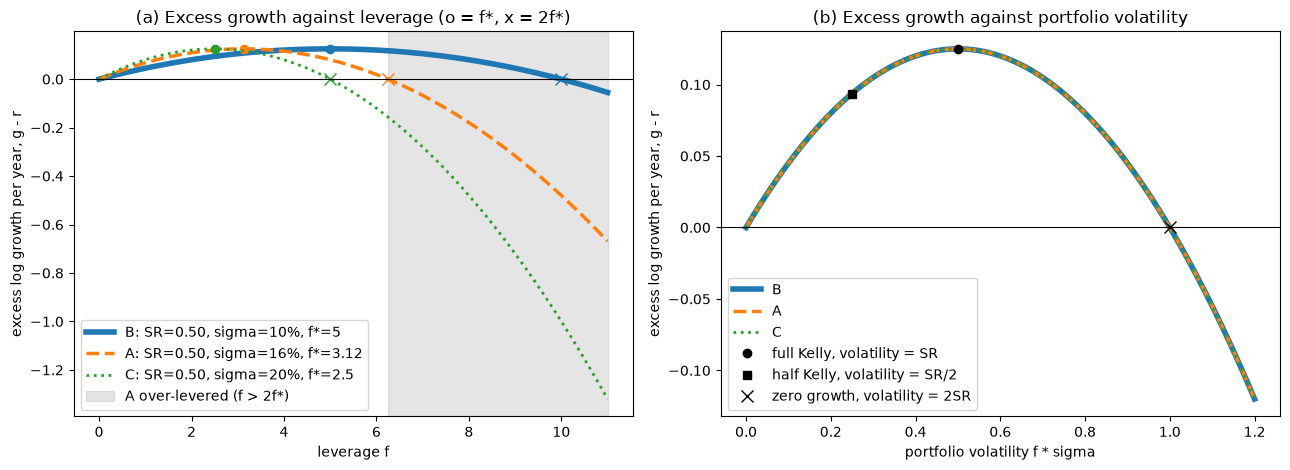

In [4]:
grid_lev = np.linspace(0, 11, 400)
grid_vol = np.linspace(0, 1.2, 400)
styles = {"B": ("-", 4), "A": ("--", 2.5), "C": (":", 2)}
fig, (ax_lev, ax_vol) = plt.subplots(1, 2, figsize=(13, 4.8))
for name, (ls, lw) in styles.items():
    excess, vol = strategies[name]
    sr_s = excess / vol
    f_star = sr_s / vol
    line, = ax_lev.plot(grid_lev, excess_growth(grid_lev, sr_s, vol), ls, lw=lw,
                        label=f"{name}: SR={sr_s:.2f}, sigma={vol:.0%}, f*={f_star:.3g}")
    ax_lev.plot([f_star], [excess_growth(f_star, sr_s, vol)], "o", color=line.get_color())
    ax_lev.plot([2 * f_star], [0], "x", color=line.get_color(), ms=9)
    ax_vol.plot(grid_vol, excess_growth(grid_vol / vol, sr_s, vol), ls, lw=lw, label=f"{name}")
f_a = strategies["A"][0] / strategies["A"][1] ** 2
ax_lev.axvspan(2 * f_a, grid_lev[-1], color="grey", alpha=0.2, label="A over-levered (f > 2f*)")
ax_lev.axhline(0, color="black", lw=0.8)
ax_lev.set_title("(a) Excess growth against leverage (o = f*, x = 2f*)")
ax_lev.set_xlabel("leverage f")
ax_lev.set_ylabel("excess log growth per year, g - r")
ax_lev.legend()
sr_a = strategies["A"][0] / strategies["A"][1]
half_vol = sr_a / 2
ax_vol.plot([sr_a], [sr_a**2 / 2], "o", color="black", label="full Kelly, volatility = SR")
ax_vol.plot([half_vol], [excess_growth(half_vol / strategies["A"][1], sr_a, strategies["A"][1])], "s", color="black",
            label="half Kelly, volatility = SR/2")
ax_vol.plot([2 * sr_a], [0], "x", color="black", ms=9, label="zero growth, volatility = 2SR")
ax_vol.axhline(0, color="black", lw=0.8)
ax_vol.set_title("(b) Excess growth against portfolio volatility")
ax_vol.set_xlabel("portfolio volatility f * sigma")
ax_vol.set_ylabel("excess log growth per year, g - r")
ax_vol.legend()
plt.tight_layout()
plt.show()

In panel (a) the peaks sit at $f^*=5$, $3.125$ and $2.5$, so three strategies with one Sharpe call for three different leverages. Beyond $2f^*=6.25$, where A is over-levered, its long-run growth rate falls below the cash rate $r$. In panel (b) the three curves land on one parabola, peaking at $\sigma_p=0.50$, with half Kelly at $0.25$ and the zero crossing at $1.0$. Sharpe tells us where on that parabola to stand. The raw volatility only tells us how much leverage it takes to get there.

## Drift Versus the Mean Log Return

One trap before we estimate anything. The drift $\mu$ is the mean simple return. A mean of log returns, $m_{\log}$, understates it by $\tfrac12\sigma^2$. For A, $m_{\log}=0.0872$:

$$
\begin{aligned}
\mu&=m_{\log}+\tfrac12\sigma^2=0.0872+0.0128=0.10\\
f^*_{\log}&=\frac{m_{\log}-r}{\sigma^2}=\frac{0.0872-0.02}{0.16^2}=2.625\\
\frac{f^*_{\log}}{f^*}&=\frac{2.625}{3.125}=0.84.
\end{aligned}
$$

Using the log mean understates the optimal leverage by 16%, even at a volatility of only 16%.

## Estimated Sharpe, Estimated Risk Target

Everything so far used the true $\mu$. In practice we estimate it, and we treat $\sigma$ as known because Merton (1980) showed variance is estimated far more precisely than the mean from high-frequency data. Let $\bar R$ be the average daily simple return over $T$ years of data, with $\Delta=1/252$. We use the long-only rule, so a negative estimate means we hold cash:

$$
\begin{aligned}
\hat\mu&=\frac{\bar R}{\Delta}\\
\widehat{SR}&=\frac{\hat\mu-r}{\sigma}\sim N\!\left(SR,\frac1T\right)\\
\hat f&=\frac{\max(\widehat{SR},0)}{\sigma}\\
\hat\sigma^*&=\hat f\sigma=\max(\widehat{SR},0).
\end{aligned}
$$

With normal daily returns, $\widehat{SR}$ is exactly normal with standard error $SE=1/\sqrt T$ (under GBM it's normal to a very close approximation). Lo's (2002) daily formula, $\sqrt{(1+SR^2/504)/T}$, is essentially the same. Its extra term comes from estimating the standard deviation, which we've taken as known.

With a true $SR=0.50$ and $T=3$ years, $SE=0.577$ and the 95% interval is about $[-0.63, 1.63]$. Shorting would change the picture. Any negative $\widehat{SR}$ would then also lose to cash, adding $P(\widehat{SR}<0)=19.3\%$ to both probabilities below.

Now turn that sampling error into sizing error. Let $c=\hat f/f^*$ be the fraction of the true Kelly leverage we end up holding. Using the result from the half-Kelly section:

$$
\begin{aligned}
c&=\frac{\hat f}{f^*}=\frac{\max(\widehat{SR},0)}{SR}\\
g(\hat f)-r&=\tfrac12SR^2\,c(2-c)\\
g(\hat f)<r&\iff c>2\iff\widehat{SR}>2\,SR\\
P(\widehat{SR}>2SR)&=\Phi\!\left(-\frac{SR}{SE}\right)=\Phi\!\left(-0.50\sqrt3\right)\approx19.3\%.
\end{aligned}
$$

Here $\Phi$ is the standard normal distribution function. Full Kelly sized from three years of data has about a 19% chance of landing at or beyond the zero-growth boundary. "Loses to cash" means the long-run growth rate at the sized $\hat f$ is below $r$. It doesn't mean wealth falls, and it doesn't mean any single finite path trails cash.

Half Kelly holds $\hat f/2$, so it needs a much larger error:

$$
\begin{aligned}
c&=\frac{\widehat{SR}}{2\,SR}>2\iff\widehat{SR}>4\,SR\\
P(\widehat{SR}>4SR)&=\Phi\!\left(-\frac{3\,SR}{SE}\right)=\Phi\!\left(-1.5\sqrt3\right)\approx0.47\%.
\end{aligned}
$$

Compare the second article, where the same two numbers were 18.3% and 0.15%. The estimate is also at or below zero with probability $P(\widehat{SR}<0)=19.3\%$, and then the rule sits in cash and earns exactly $r$. Thorp (2006, section 7.3) shows that if the true drift is half the estimate, full Kelly earns zero excess growth and half Kelly is exactly optimal. Selection makes this worse. The best of many backtests has an upward-biased estimate, so $c>1$ is likelier than this calculation says.

## Run a Simulation to Validate

We check the closed forms by simulation. We draw 10,000 three-year histories of normal daily returns with mean $\mu\Delta$ and standard deviation $\sigma\sqrt\Delta$, estimate $\widehat{SR}$ in each, and compare the frequencies with the closed forms to within three Monte Carlo standard errors.

In [5]:
r, mu, sigma, T, n = 0.02, 0.10, 0.16, 3, 10_000
sr, dt, days = (mu - r) / sigma, 1 / 252, 252 * T
rng = np.random.default_rng(42)
rets = rng.normal(mu * dt, sigma * np.sqrt(dt), (n, days))
sr_hat = (rets.mean(1) / dt - r) / sigma
se = 1 / np.sqrt(T)
closed = np.array([norm.cdf(-sr / se), norm.cdf(-3 * sr / se), norm.cdf(-sr / se)])
sim = np.array([(sr_hat > 2 * sr).mean(), (sr_hat > 4 * sr).mean(), (sr_hat < 0).mean()])
mcse = np.sqrt(closed * (1 - closed) / n)
tab = pd.DataFrame({"closed": closed, "simulated": sim, "mc_se": mcse, "z": (sim - closed) / mcse},
                   index=["full Kelly overbets (SR_hat > 2SR)", "half Kelly overbets (SR_hat > 4SR)", "SR_hat < 0"])
print(f"SE(SR_hat) closed {se:.4f}, simulated {sr_hat.std(ddof=1):.4f}")
print(tab.round(4).to_string())
assert (tab.z.abs() < 3).all()

SE(SR_hat) closed 0.5774, simulated 0.5723
                                    closed  simulated   mc_se       z
full Kelly overbets (SR_hat > 2SR)  0.1932     0.1968  0.0039  0.9021
half Kelly overbets (SR_hat > 4SR)  0.0047     0.0033  0.0007 -2.0312
SR_hat < 0                          0.1932     0.1882  0.0039 -1.2760


The simulation agrees with the closed forms. The simulated standard error of $\widehat{SR}$ matches $1/\sqrt3$. Full Kelly overbets in about 19.7% of histories against 19.3% in theory, and the half Kelly tail is 0.33% against 0.47%. That tail is only 33 histories in 10,000, so its z-score is noisy but inside tolerance.

## Caveats

Everything above lives inside a model: the assumptions listed with the optimum, plus Brownian dynamics with no jumps or fat tails, and known parameters until the estimation section. A backtest's $\widehat{SR}$ is one noisy draw. The formulas need the population $SR$, which we never observe, so every risk target in practice is an estimate. With discrete rebalancing $f^*$ is only an approximation, though the daily and monthly checks above put the true optimum within about 1% of it. Margin limits and financing spreads above $r$ put a kink in $g$ for $f>1$ and push the best leverage lower. Square-root-of-time annualisation needs IID returns (Lo, 2002). Kan and Zhou (2007) show that parameter uncertainty changes the optimal rule itself, not just the size of the error, so shrinkage, fractional Kelly and sizing rules built for parameter uncertainty are the natural next steps.

# Conclusion

Sharpe ranks strategies. Under a clean continuous-time model it also fixes the growth-optimal volatility target, which equals the Sharpe ratio when both sit on the same horizon. Volatility turns that target into leverage, $SR/\sigma$. Strategy A, with a Sharpe of 0.50, targets 50% volatility, and B and C reach the same target with 5 and 2.5 times leverage. The target inherits every error in the estimated Sharpe. With three years of data there's a 19% chance of holding more than twice the right exposure, and half Kelly cuts that to under 0.5%.

## References

1. Kelly, J. L., Jr. (1956). *A New Interpretation of Information Rate*. Bell System Technical Journal, 35(4), 917-926. https://doi.org/10.1002/j.1538-7305.1956.tb03809.x
2. Breiman, L. (1961). *Optimal Gambling Systems for Favorable Games*. Proceedings of the Fourth Berkeley Symposium on Mathematical Statistics and Probability, 1, 65-78. https://projecteuclid.org/proceedings/berkeley-symposium-on-mathematical-statistics-and-probability/Proceedings-of-the-Fourth-Berkeley-Symposium-on-Mathematical-Statistics-and/Chapter/Optimal-Gambling-Systems-for-Favorable-Games/bsmsp/1200512159
3. Merton, R. C. (1969). *Lifetime Portfolio Selection under Uncertainty: The Continuous-Time Case*. Review of Economics and Statistics, 51(3), 247-257. https://doi.org/10.2307/1926560
4. Merton, R. C. (1971). *Optimum Consumption and Portfolio Rules in a Continuous-Time Model*. Journal of Economic Theory, 3(4), 373-413. https://doi.org/10.1016/0022-0531(71)90038-X
5. Merton, R. C. (1980). *On Estimating the Expected Return on the Market: An Exploratory Investigation*. Journal of Financial Economics, 8(4), 323-361. https://doi.org/10.1016/0304-405X(80)90007-0
6. Sharpe, W. F. (1966). *Mutual Fund Performance*. Journal of Business, 39(1), 119-138. https://doi.org/10.1086/294846
7. Sharpe, W. F. (1994). *The Sharpe Ratio*. Journal of Portfolio Management, 21(1), 49-58. https://doi.org/10.3905/jpm.1994.409501
8. Lo, A. W. (2002). *The Statistics of Sharpe Ratios*. Financial Analysts Journal, 58(4), 36-52. https://doi.org/10.2469/faj.v58.n4.2453
9. Thorp, E. O. (2006). *The Kelly Criterion in Blackjack, Sports Betting, and the Stock Market*. Handbook of Asset and Liability Management, 1, 385-428. https://doi.org/10.1016/S1872-0978(06)01009-X
10. MacLean, L. C., Thorp, E. O., and Ziemba, W. T. (2010). *Long-Term Capital Growth: The Good and Bad Properties of the Kelly and Fractional Kelly Capital Growth Criteria*. Quantitative Finance, 10(7), 681-687. https://doi.org/10.1080/14697688.2010.506108
11. Kan, R., and Zhou, G. (2007). *Optimal Portfolio Choice with Parameter Uncertainty*. Journal of Financial and Quantitative Analysis, 42(3), 621-656. https://doi.org/10.1017/S0022109000004129
12. Cover, T. M., and Thomas, J. A. (2006). *Elements of Information Theory* (2nd ed.), chapter 16, "Information Theory and Portfolio Theory". Wiley. ISBN 978-0-471-24195-9.

# GitHub

This article is also available on [GitHub](https://github.com/adamd1985/quant_research/blob/main/sharpe_as_risk_target.ipynb)

Kaggle notebook available [here](https://www.kaggle.com/code/addarm/sharpe-as-risk-target)

# Media

All media used (in the form of code or images) are either solely owned by me, acquired through licensing, or part of the Public Domain and granted use through Creative Commons License.

# CC Licensing and Use

<a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/"><img alt="Creative Commons License" style="border-width:0" src="https://i.creativecommons.org/l/by-nc/4.0/88x31.png" /></a><br />This work is licensed under a <a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/">Creative Commons Attribution-NonCommercial 4.0 International License</a>.